# MoE IVN-IDS: Continual Learning Evaluation Report

Evaluate trained models across all phases and generate visual reports.

**Outputs:**
- Per-class F1 heatmap
- Macro F1 progression
- Forgetting analysis
- Confusion matrices
- Cls entropy distributions
- Expert growth
- Summary table


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path('../').resolve()))
print(sys.path[:3])

['/home/hieutt/MoE-IVN-IDS', '/home/hieutt/MoE-IVN-IDS/notebooks', '/home/hieutt/miniconda3/envs/torchtf/lib/python39.zip']


In [3]:
# ============================================================
# Configuration - EDIT THESE PATHS
# ============================================================

DATA_DIR = "../data/2011-chevrolet-impala/preprocessed"

# Add all configs you want to compare
CONFIGS = {
    "MoE Cosine": "../save/ablation_final/impala/std_moe_s42",
    # "Dense + Replay": "./save/baselines/2011-chevrolet-impala/dense_replay_variant",
    # "MoE FT + Replay": "./save/baselines/2011-chevrolet-impala/moe_ft_replay_variant",
}
GPU = 0
BATCH_SIZE = 256
NUM_WORKERS = 4

# Model defaults (match training config)
EMBED_DIM = 16
MOE_OUT_DIM = 128
TOP_K = 2
DROPOUT = 0.2
NUM_EXPERTS_BASE = 6


In [4]:
import json, os, sys
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from sklearn.metrics import confusion_matrix
from tqdm.notebook import tqdm

from networks.moe_ivn_ids_cosine import MoEIVNIDS
from utils import (NUM_CLASSES, WindowDataset, collate_fn, compute_metrics,
                   get_class_names, load_metadata, load_windows, set_seed)

set_seed(42)
CLASS_NAMES = get_class_names()

if torch.cuda.is_available():
    torch.cuda.set_device(GPU)
    device = torch.device(f"cuda:{GPU}")
else:
    device = torch.device("cpu")
print(f"Device: {device}")

plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
})


Device: cuda:0


In [5]:
# Phase definitions
PHASES = [
    {"name": "phase1", "attacks": [0, 1, 2, 3, 4, 5],
     "desc": "Base: normal + dos(p1) + fuzzing + gear + interval + rpm"},
    {"name": "phase2", "new_attacks": [6], "type": "new",
     "desc": "New: speed"},
    {"name": "phase3", "new_attacks": [1], "type": "variant",
     "desc": "Variant: dos(p2)"},
    {"name": "phase4", "new_attacks": [7], "type": "new",
     "desc": "New: standstill"},
    {"name": "phase5", "new_attacks": [8, 9], "type": "new",
     "desc": "New: systematic + combined"},
]

# Load data
meta = load_metadata(Path(DATA_DIR) / "metadata.json")
all_train = load_windows(Path(DATA_DIR) / "windows_train.pt")
all_val = load_windows(Path(DATA_DIR) / "windows_val.pt")
all_test = load_windows(Path(DATA_DIR) / "windows_test.pt")
print(f"Data loaded: train={len(all_train)}, val={len(all_val)}, test={len(all_test)}")


  Loaded 85304 windows from ../data/2011-chevrolet-impala/preprocessed/windows_train.pt
  Loaded 28434 windows from ../data/2011-chevrolet-impala/preprocessed/windows_val.pt
  Loaded 28433 windows from ../data/2011-chevrolet-impala/preprocessed/windows_test.pt
Data loaded: train=85304, val=28434, test=28433


In [6]:
@torch.no_grad()
def evaluate_model(model, loader, device):
    model.eval()
    all_preds, all_labels, all_cls_ent = [], [], []
    for batch in tqdm(loader, desc="Evaluating", leave=False):
        xl = [x.to(device) for x in batch["x_list"]]
        al = [a.to(device) for a in batch["adj_list"]]
        il = [i.to(device) for i in batch["id_idx_list"]]
        y = batch["y"]
        with torch.amp.autocast('cuda', enabled=device.type == 'cuda'):
            out = model(xl, al, il)
        all_preds.extend(out["logits"].float().argmax(1).cpu().tolist())
        all_labels.extend(y.tolist())
        all_cls_ent.extend(out["cls_entropy"].float().cpu().tolist())
    return np.array(all_labels), np.array(all_preds), np.array(all_cls_ent)


def per_class_f1(y_true, y_pred, classes):
    result = {}
    for c in classes:
        mask = y_true == c
        if mask.sum() > 0:
            m = compute_metrics(y_true[mask], y_pred[mask])
            result[CLASS_NAMES[c]] = m["macro_f1"]
        else:
            result[CLASS_NAMES[c]] = 0.0
    return result


def load_phase_model(ckpt_path, num_experts):
    model = MoEIVNIDS(
        vocab_size=meta["vocab_size"], num_features=meta["num_features"],
        embed_dim=EMBED_DIM, num_experts=num_experts,
        top_k=TOP_K, moe_out_dim=MOE_OUT_DIM, dropout=DROPOUT,
    ).to(device)
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model"])
    return model, ckpt


## 1. Evaluate All Phases

In [7]:
# Evaluate all phases for each config
all_results = {}

for config_name, save_dir in CONFIGS.items():
    print(f"\n{'='*60}")
    print(f"Config: {config_name}")
    print(f"{'='*60}")

    phase_f1 = {}
    macro_f1s = {}
    phase_preds = {}
    phase_entropy = {}
    decisions = []
    seen = set()

    for pi, phase in enumerate(PHASES):
        pname = phase["name"]
        ckpt_path = os.path.join(save_dir, f"{pname}_best.pth")
        if not os.path.exists(ckpt_path):
            print(f"  [{pname}] Checkpoint not found, skipping")
            continue

        if pi == 0:
            seen = set(phase["attacks"])
        else:
            seen.update(phase["new_attacks"])

        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        n_exp = ckpt.get("num_experts", NUM_EXPERTS_BASE)
        model, _ = load_phase_model(ckpt_path, n_exp)

        test_data = [w for w in all_test if w["label"] in seen]
        loader = DataLoader(WindowDataset(test_data), BATCH_SIZE,
                            shuffle=False, collate_fn=collate_fn,
                            num_workers=NUM_WORKERS, pin_memory=True)

        y_true, y_pred, cls_ent = evaluate_model(model, loader, device)
        metrics = compute_metrics(y_true, y_pred)
        pf1 = per_class_f1(y_true, y_pred, sorted(seen))

        phase_f1[pname] = pf1
        macro_f1s[pname] = metrics["macro_f1"]
        phase_preds[pname] = (y_true, y_pred, sorted(seen))
        phase_entropy[pname] = cls_ent

        expanded = n_exp > (decisions[-1]["n_exp"] if decisions else NUM_EXPERTS_BASE)
        decisions.append({
            "phase": pname, "n_exp": n_exp,
            "decision": "expand" if (pi > 0 and expanded) else ("initial" if pi == 0 else "no_expand"),
            "desc": phase.get("desc", ""), "f1": metrics["macro_f1"],
        })

        print(f"  [{pname}] F1={metrics['macro_f1']:.4f} | experts={n_exp} | {phase.get('desc','')}")
        del model

    all_results[config_name] = {
        "phase_f1": phase_f1, "macro_f1s": macro_f1s,
        "phase_preds": phase_preds, "phase_entropy": phase_entropy,
        "decisions": decisions,
    }



Config: MoE Cosine


Evaluating:   0%|          | 0/93 [00:00<?, ?it/s]

  [phase1] F1=0.9862 | experts=4 | Base: normal + dos(p1) + fuzzing + gear + interval + rpm


Evaluating:   0%|          | 0/99 [00:00<?, ?it/s]

  [phase2] F1=0.9826 | experts=5 | New: speed
  [phase3] Checkpoint not found, skipping


Evaluating:   0%|          | 0/101 [00:00<?, ?it/s]

  [phase4] F1=0.9771 | experts=6 | New: standstill


Evaluating:   0%|          | 0/112 [00:00<?, ?it/s]

  [phase5] F1=0.9755 | experts=7 | New: systematic + combined


## 2. Per-Class F1 Heatmap

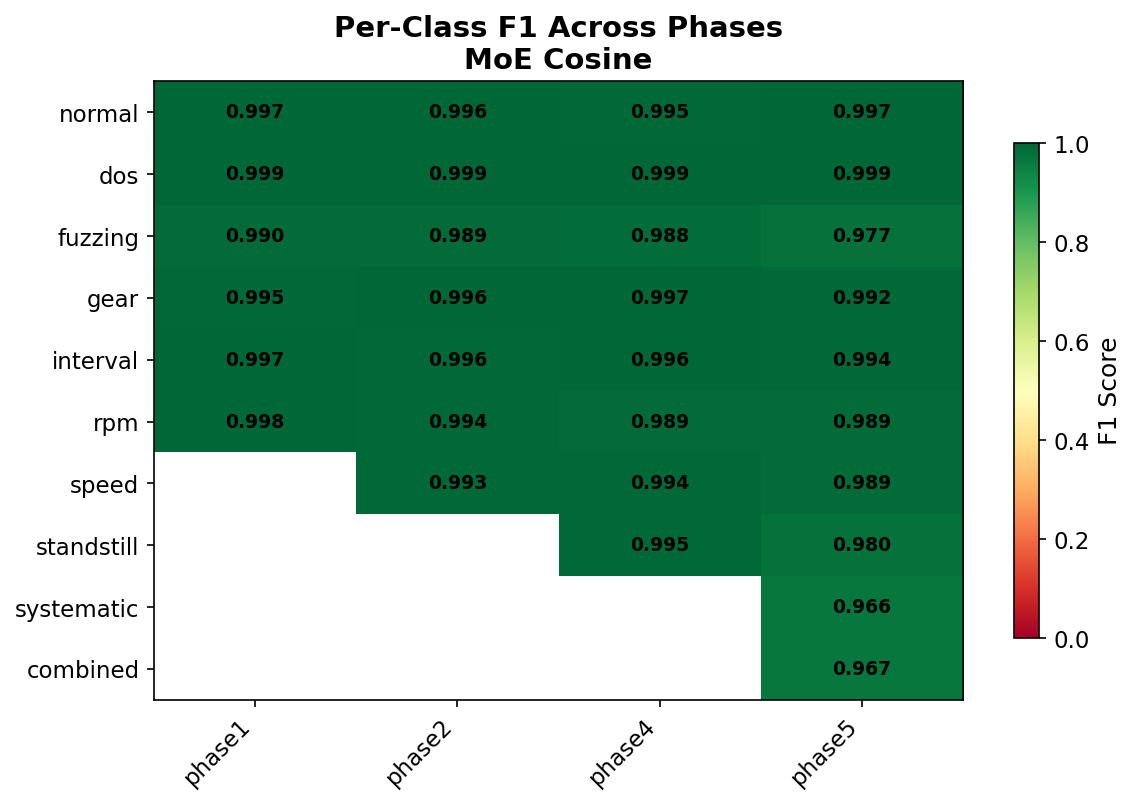

In [8]:
for config_name, res in all_results.items():
    phase_f1 = res["phase_f1"]
    phases = list(phase_f1.keys())
    all_classes = []
    for r in phase_f1.values():
        for c in r:
            if c not in all_classes:
                all_classes.append(c)

    data = np.full((len(all_classes), len(phases)), np.nan)
    for j, phase in enumerate(phases):
        for i, cls in enumerate(all_classes):
            if cls in phase_f1[phase]:
                data[i, j] = phase_f1[phase][cls]

    fig, ax = plt.subplots(figsize=(max(8, len(phases)*1.8), max(5, len(all_classes)*0.55)))
    cmap = plt.cm.RdYlGn.copy()
    cmap.set_bad('white')
    im = ax.imshow(data, cmap=cmap, vmin=0.0, vmax=1.0, aspect='auto')

    ax.set_xticks(range(len(phases)))
    ax.set_xticklabels(phases, rotation=45, ha='right')
    ax.set_yticks(range(len(all_classes)))
    ax.set_yticklabels(all_classes)

    for i in range(len(all_classes)):
        for j in range(len(phases)):
            if not np.isnan(data[i, j]):
                v = data[i, j]
                color = 'white' if v < 0.5 else 'black'
                ax.text(j, i, f'{v:.3f}', ha='center', va='center',
                        fontsize=9, color=color, fontweight='bold')

    plt.colorbar(im, ax=ax, label='F1 Score', shrink=0.8)
    ax.set_title(f'Per-Class F1 Across Phases\n{config_name}', fontweight='bold')
    plt.tight_layout()
    plt.show()


## 3. Macro F1 Progression

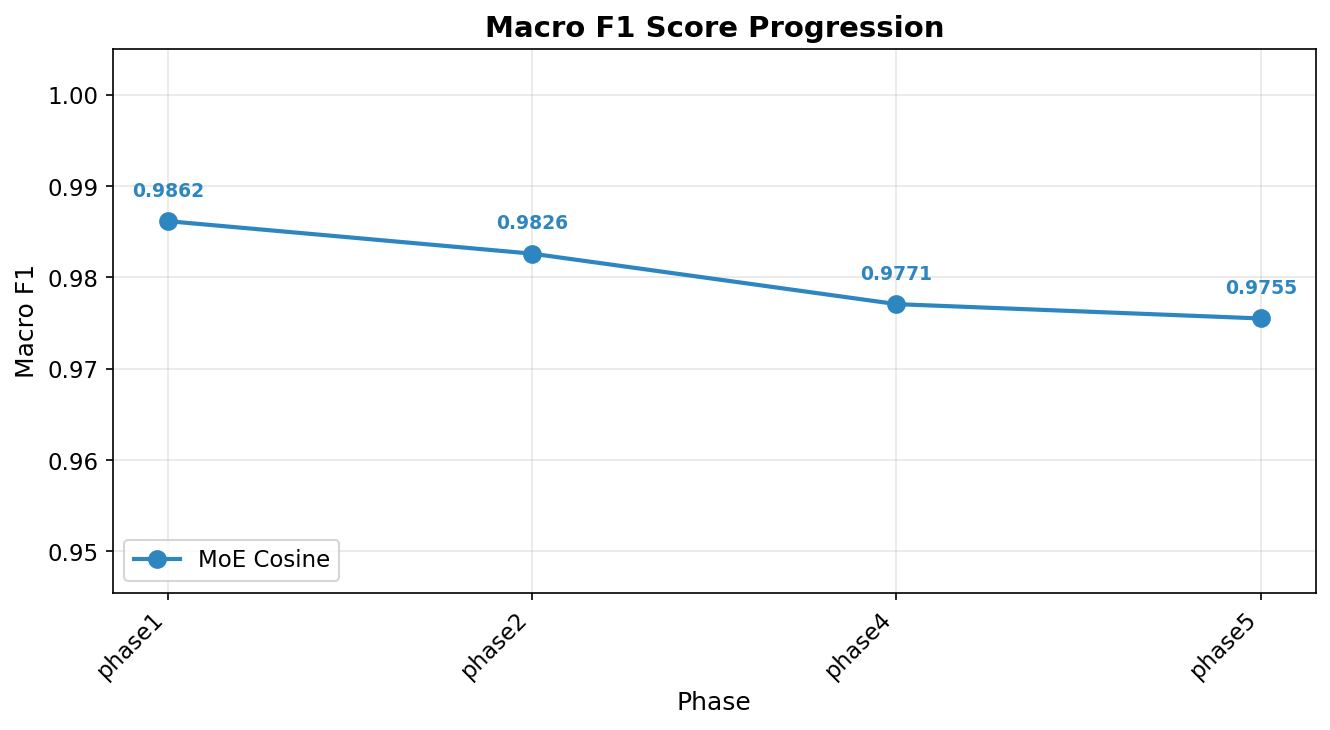

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2E86C1', '#E74C3C', '#27AE60', '#F39C12', '#8E44AD']

for idx, (config_name, res) in enumerate(all_results.items()):
    phases = list(res["macro_f1s"].keys())
    values = list(res["macro_f1s"].values())
    c = colors[idx % len(colors)]
    ax.plot(phases, values, 'o-', color=c, linewidth=2, markersize=8, label=config_name)
    for i, v in enumerate(values):
        ax.annotate(f'{v:.4f}', (i, v), textcoords="offset points",
                    xytext=(0, 12), ha='center', fontsize=9, fontweight='bold', color=c)

ax.set_ylim(min(min(r["macro_f1s"].values()) for r in all_results.values()) - 0.03, 1.005)
ax.set_xlabel('Phase')
ax.set_ylabel('Macro F1')
ax.set_title('Macro F1 Score Progression', fontweight='bold')
ax.legend(loc='lower left')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 4. Forgetting Analysis

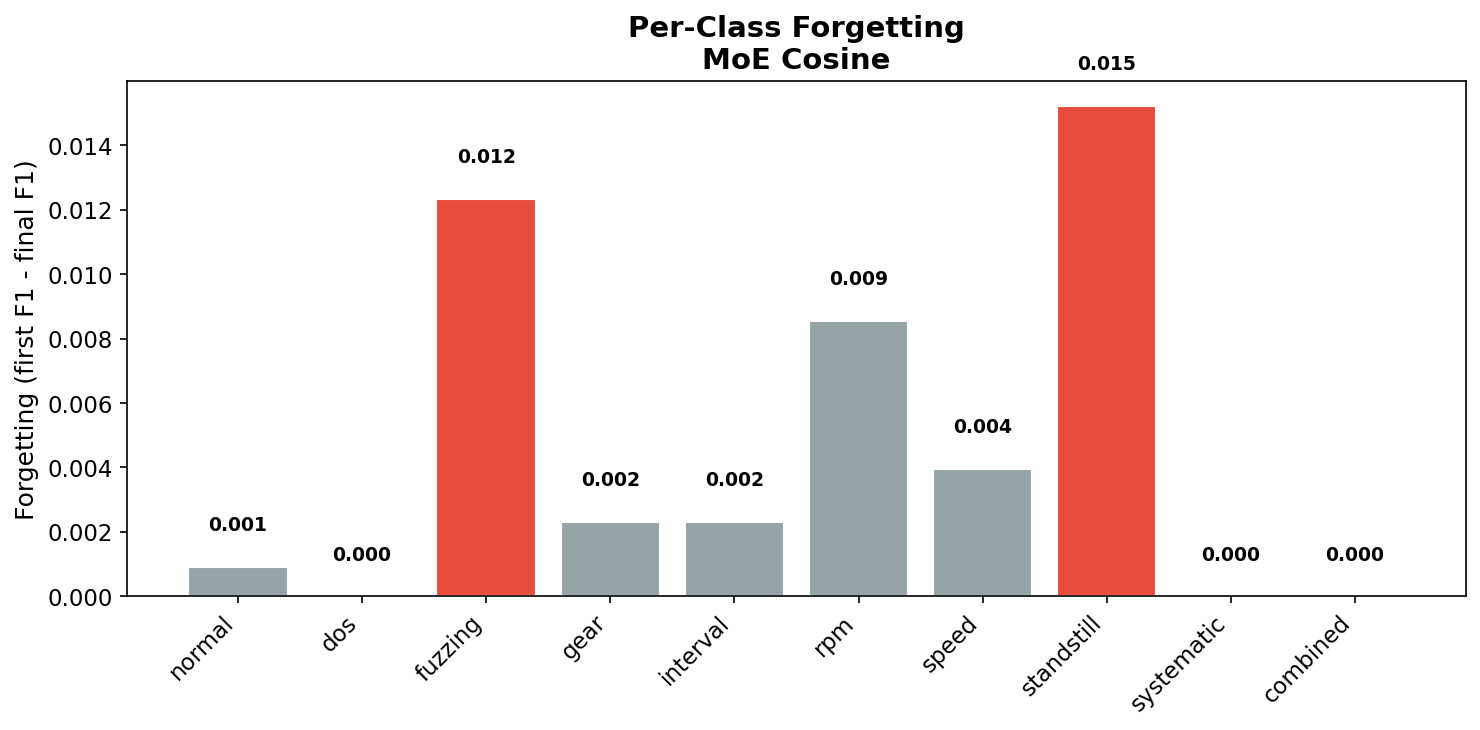

In [10]:
for config_name, res in all_results.items():
    phase_f1 = res["phase_f1"]
    phases = list(phase_f1.keys())
    all_classes = []
    first_f1, final_f1 = {}, {}
    for phase in phases:
        for cls, f1 in phase_f1[phase].items():
            if cls not in all_classes:
                all_classes.append(cls)
                first_f1[cls] = f1
            final_f1[cls] = f1

    forgetting = [first_f1[c] - final_f1[c] for c in all_classes]
    colors_bar = ['#E74C3C' if f > 0.01 else '#27AE60' if f < -0.01 else '#95A5A6'
                  for f in forgetting]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(all_classes, forgetting, color=colors_bar, edgecolor='white')
    for bar, f in zip(bars, forgetting):
        y = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, y + 0.001,
                f'{f:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_ylabel('Forgetting (first F1 - final F1)')
    ax.set_title(f'Per-Class Forgetting\n{config_name}', fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


## 5. Confusion Matrices

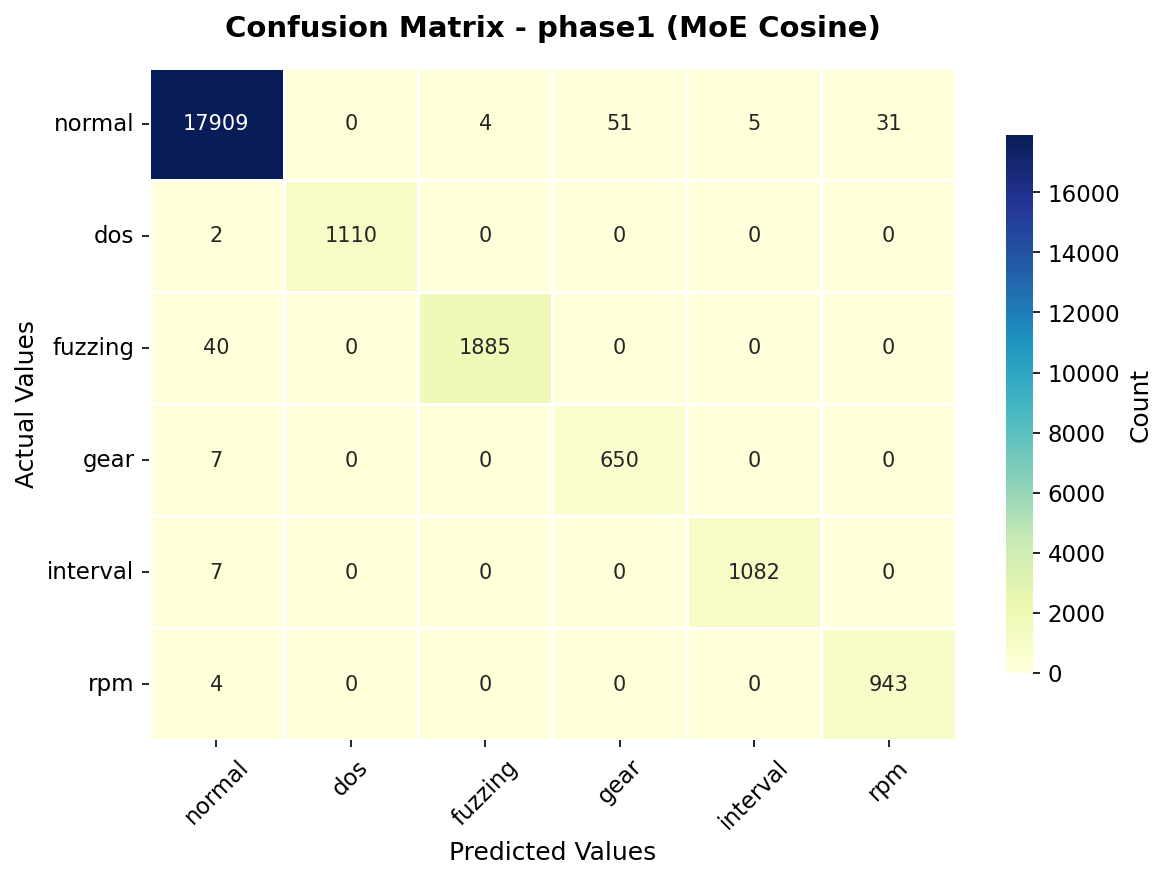

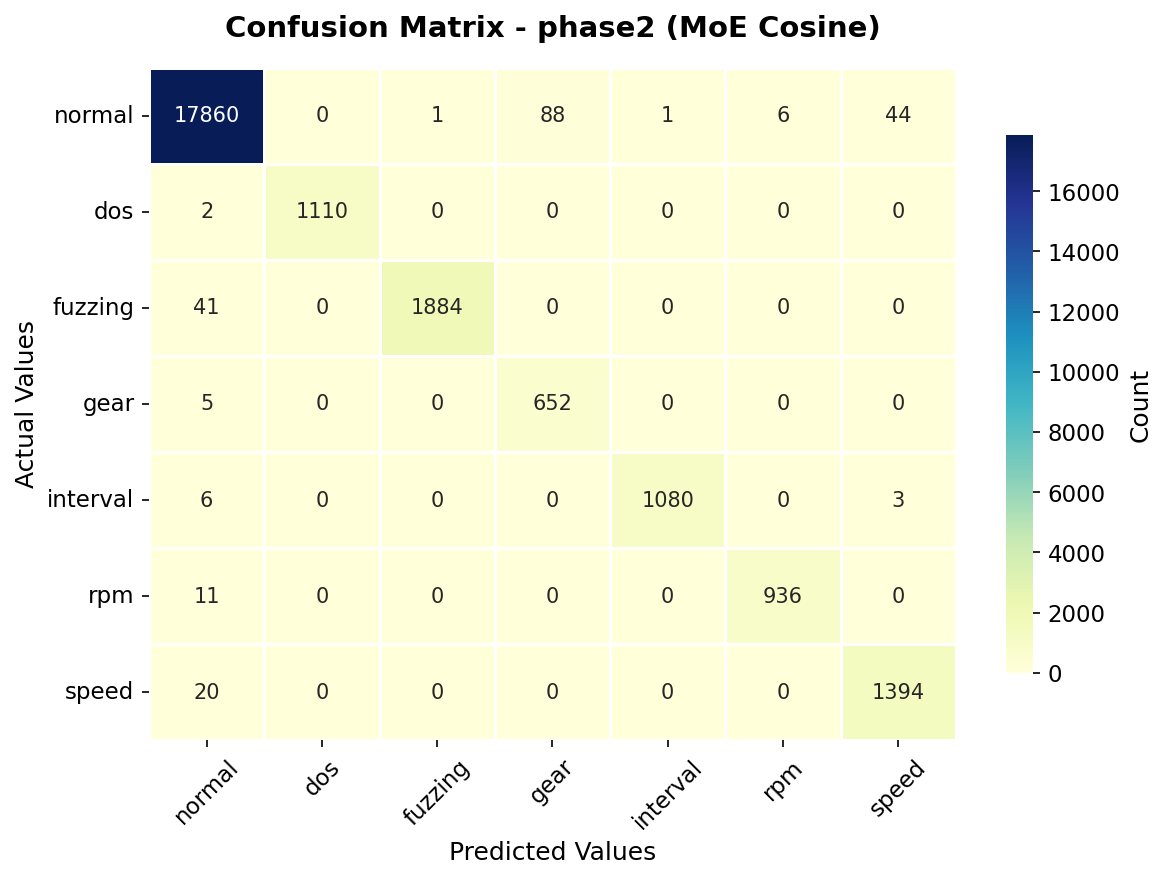

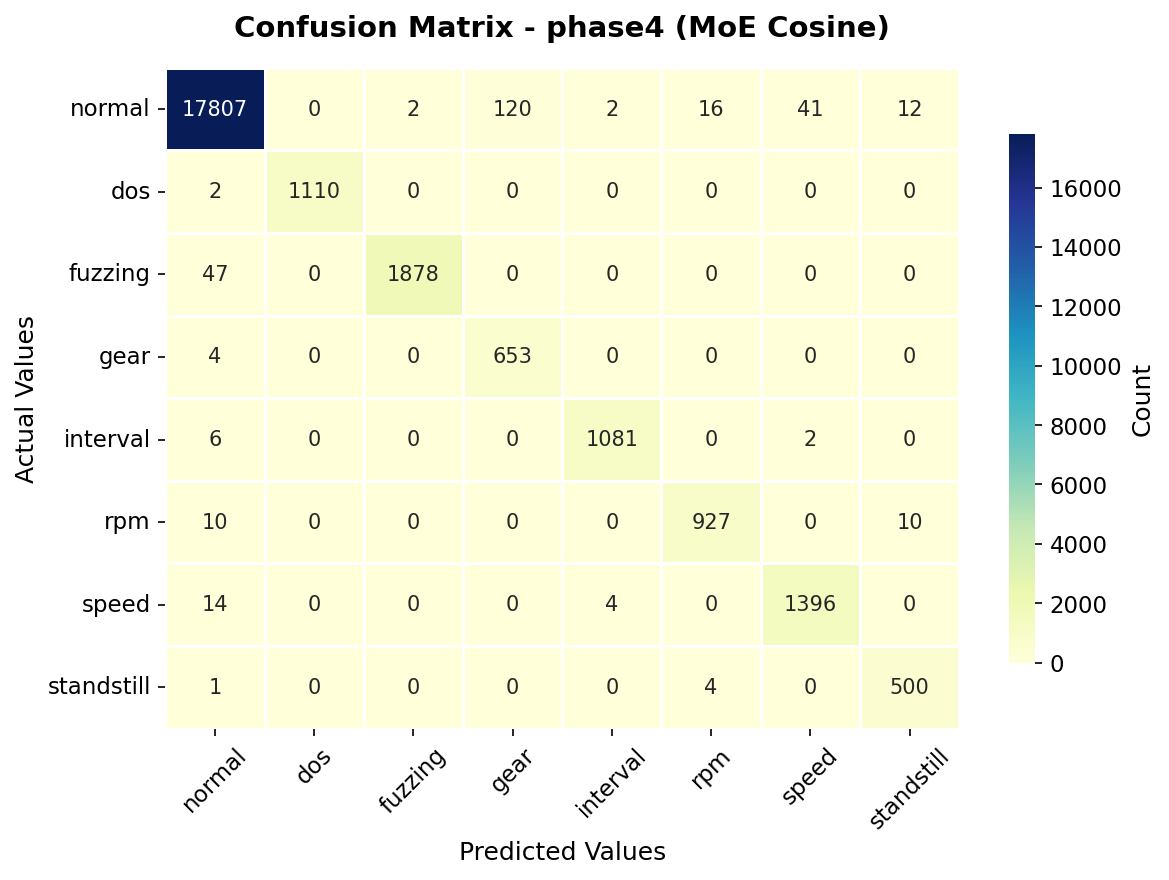

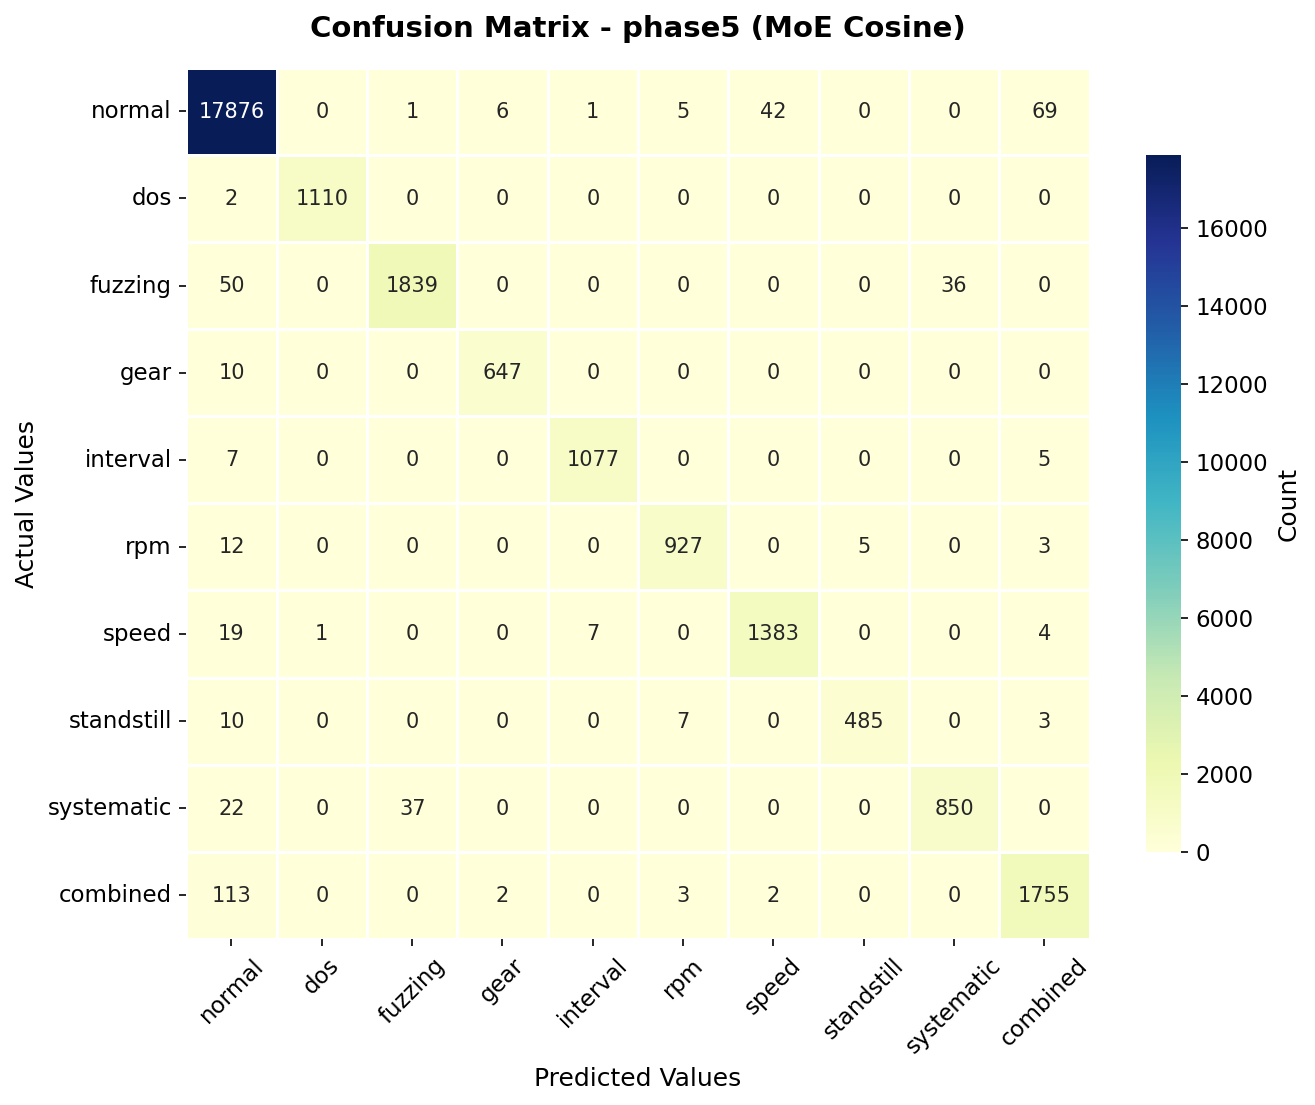

In [11]:
for config_name, res in all_results.items():
    phase_preds = res["phase_preds"]

    for pname, (y_true, y_pred, seen_cls) in phase_preds.items():
        labels = seen_cls
        names = [CLASS_NAMES[c] for c in labels]
        cm = confusion_matrix(y_true, y_pred, labels=labels)
        n = len(names)

        fig, ax = plt.subplots(figsize=(max(8, n * 0.9), max(6, n * 0.75)))

        sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
                    xticklabels=names, yticklabels=names,
                    linewidths=0.5, linecolor='white',
                    cbar_kws={'shrink': 0.8, 'label': 'Count'},
                    annot_kws={'size': 10},
                    ax=ax)

        ax.set_xlabel('Predicted Values', fontsize=12)
        ax.set_ylabel('Actual Values', fontsize=12)
        ax.set_title(f'Confusion Matrix - {pname} ({config_name})',
                     fontsize=14, fontweight='bold', pad=15)
        ax.tick_params(axis='x', rotation=45)
        ax.tick_params(axis='y', rotation=0)
        plt.tight_layout()
        plt.show()

## 6. Expert Growth & Decisions

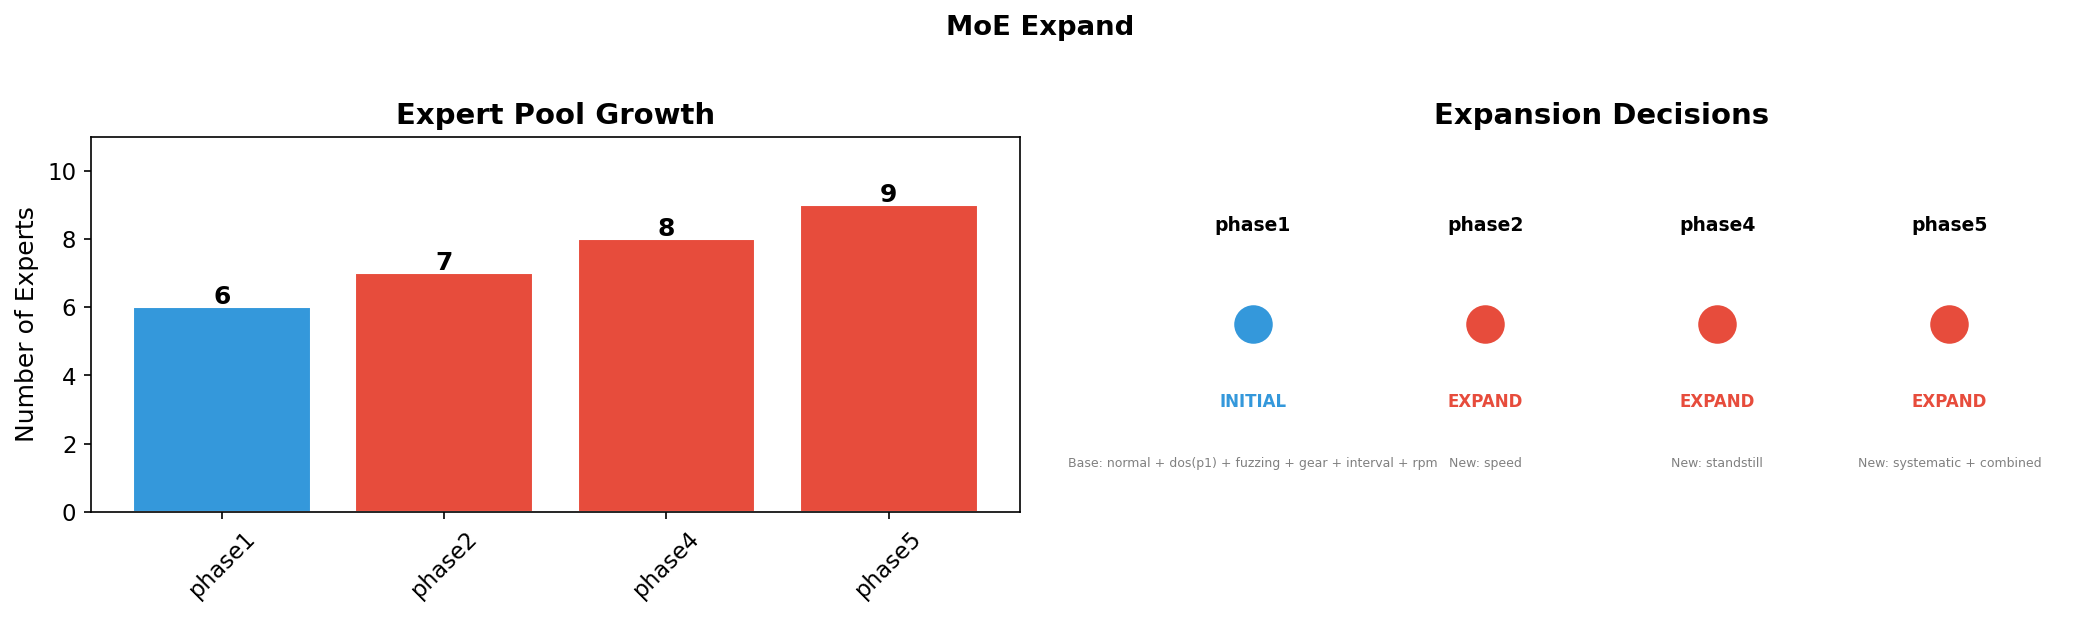

In [11]:
for config_name, res in all_results.items():
    decisions = res["decisions"]
    phases = [d["phase"] for d in decisions]
    experts = [d["n_exp"] for d in decisions]
    colors_bar = []
    for d in decisions:
        if d["decision"] == "expand":
            colors_bar.append('#E74C3C')
        elif d["decision"] == "initial":
            colors_bar.append('#3498DB')
        else:
            colors_bar.append('#95A5A6')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

    # Expert growth
    ax1.bar(phases, experts, color=colors_bar, edgecolor='white')
    for i, e in enumerate(experts):
        ax1.text(i, e + 0.1, str(e), ha='center', fontweight='bold', fontsize=12)
    ax1.set_ylabel('Number of Experts')
    ax1.set_title('Expert Pool Growth', fontweight='bold')
    ax1.set_ylim(0, max(experts) + 2)
    ax1.tick_params(axis='x', rotation=45)

    # Decision timeline
    for i, d in enumerate(decisions):
        c = '#E74C3C' if d["decision"] == "expand" else '#3498DB' if d["decision"] == "initial" else '#95A5A6'
        ax2.scatter(i, 0.5, s=400, c=c, zorder=5, edgecolors='white', linewidth=1.5)
        ax2.text(i, 0.75, d["phase"], ha='center', fontsize=9, fontweight='bold')
        ax2.text(i, 0.28, d["decision"].upper(), ha='center', fontsize=8, color=c, fontweight='bold')
        ax2.text(i, 0.12, d["desc"], ha='center', fontsize=6, color='gray')
    ax2.set_xlim(-0.5, len(decisions) - 0.5)
    ax2.set_ylim(0, 1)
    ax2.axis('off')
    ax2.set_title('Expansion Decisions', fontweight='bold')

    fig.suptitle(config_name, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


## 6b. Routing Heatmap (Expert × Class)

Shows which experts handle which attack classes. Each cell = average routing weight for that (class, expert) pair. Helps understand expert specialization.

Routing analysis:   0%|          | 0/112 [00:00<?, ?it/s]

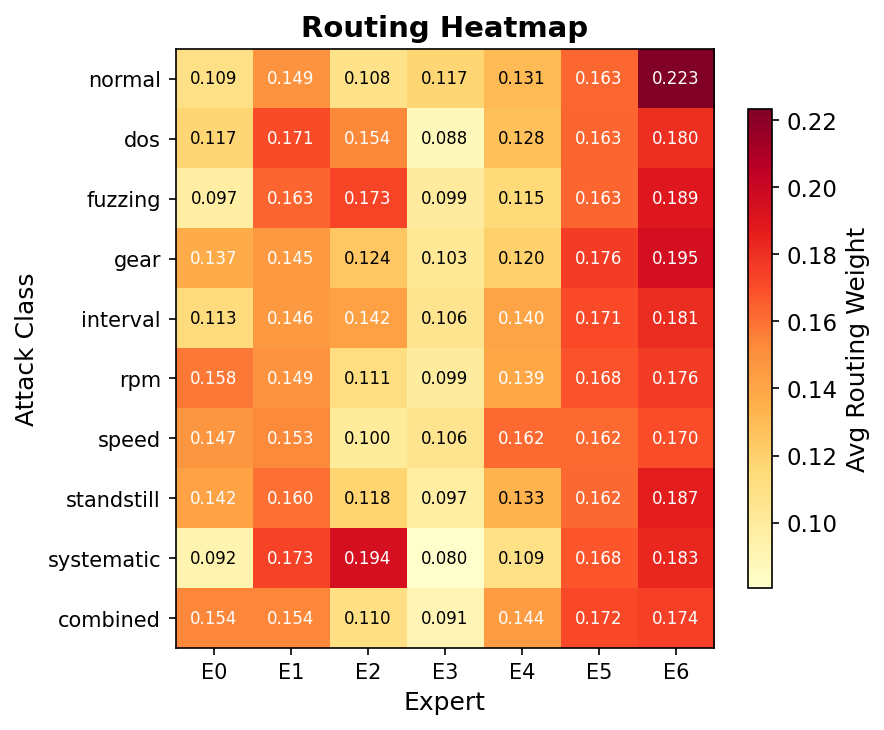

In [12]:
@torch.no_grad()
def compute_routing_heatmap(model, loader, device, num_experts):
    """Compute average routing weights per class."""
    model.eval()
    # class_idx -> list of routing weight vectors [M]
    class_routing = defaultdict(list)

    for batch in tqdm(loader, desc="Routing analysis", leave=False):
        xl = [x.to(device) for x in batch["x_list"]]
        al = [a.to(device) for a in batch["adj_list"]]
        il = [i.to(device) for i in batch["id_idx_list"]]
        y = batch["y"]

        sizes = [x.size(0) for x in xl]
        x_cat = torch.cat(xl, dim=0)
        ids_cat = torch.cat(il, dim=0)
        embed_cat = model.id_embedding(ids_cat)
        input_cat = torch.cat([x_cat, embed_cat], dim=-1)

        with torch.amp.autocast('cuda', enabled=device.type == 'cuda'):
            weights, _, _ = model.moe.router(input_cat)

        # Split per graph, compute mean routing per graph
        w_split = torch.split(weights.float(), sizes)
        for gi, label in enumerate(y.tolist()):
            graph_routing = w_split[gi].mean(0).cpu().numpy()  # [M]
            class_routing[label].append(graph_routing)

    # Average per class
    heatmap = {}
    for cls_idx, routing_list in class_routing.items():
        heatmap[cls_idx] = np.mean(routing_list, axis=0)  # [M]
    return heatmap


# Compute routing heatmap for final phase of each config
for config_name, res in all_results.items():
    decisions = res["decisions"]
    last_phase = decisions[-1]["phase"]
    last_n_exp = decisions[-1]["n_exp"]
    save_dir = CONFIGS[config_name]

    ckpt_path = os.path.join(save_dir, f"{last_phase}_best.pth")
    if not os.path.exists(ckpt_path):
        print(f"Skipping {config_name}: no checkpoint for {last_phase}")
        continue

    model, _ = load_phase_model(ckpt_path, last_n_exp)
    seen = set()
    for phase in PHASES:
        if "attacks" in phase:
            seen.update(phase["attacks"])
        else:
            seen.update(phase["new_attacks"])

    test_data = [w for w in all_test if w["label"] in seen]
    loader = DataLoader(WindowDataset(test_data), BATCH_SIZE,
                        shuffle=False, collate_fn=collate_fn,
                        num_workers=NUM_WORKERS, pin_memory=True)

    heatmap = compute_routing_heatmap(model, loader, device, last_n_exp)

    # Build matrix: [num_classes x num_experts]
    class_order = sorted(heatmap.keys())
    class_labels = [CLASS_NAMES[c] for c in class_order]
    data = np.array([heatmap[c] for c in class_order])

    fig, ax = plt.subplots(figsize=(max(6, last_n_exp * 0.8), max(4, len(class_order) * 0.5)))
    im = ax.imshow(data, cmap='YlOrRd', aspect='auto')

    ax.set_xticks(range(last_n_exp))
    ax.set_xticklabels([f'E{i}' for i in range(last_n_exp)], fontsize=10)
    ax.set_yticks(range(len(class_labels)))
    ax.set_yticklabels(class_labels, fontsize=10)

    for ii in range(len(class_labels)):
        for jj in range(last_n_exp):
            v = data[ii, jj]
            color = 'white' if v > data.max() * 0.6 else 'black'
            ax.text(jj, ii, f'{v:.3f}', ha='center', va='center',
                    fontsize=8, color=color)

    plt.colorbar(im, ax=ax, label='Avg Routing Weight', shrink=0.8)
    ax.set_xlabel('Expert')
    ax.set_ylabel('Attack Class')
    ax.set_title(f'Routing Heatmap', fontweight='bold')
    plt.tight_layout()
    plt.show()
    del model


## 6c. Classification Entropy Analysis

Shows cls entropy distribution per class, and known vs novel comparison for each expand phase.

Evaluating:   0%|          | 0/112 [00:00<?, ?it/s]

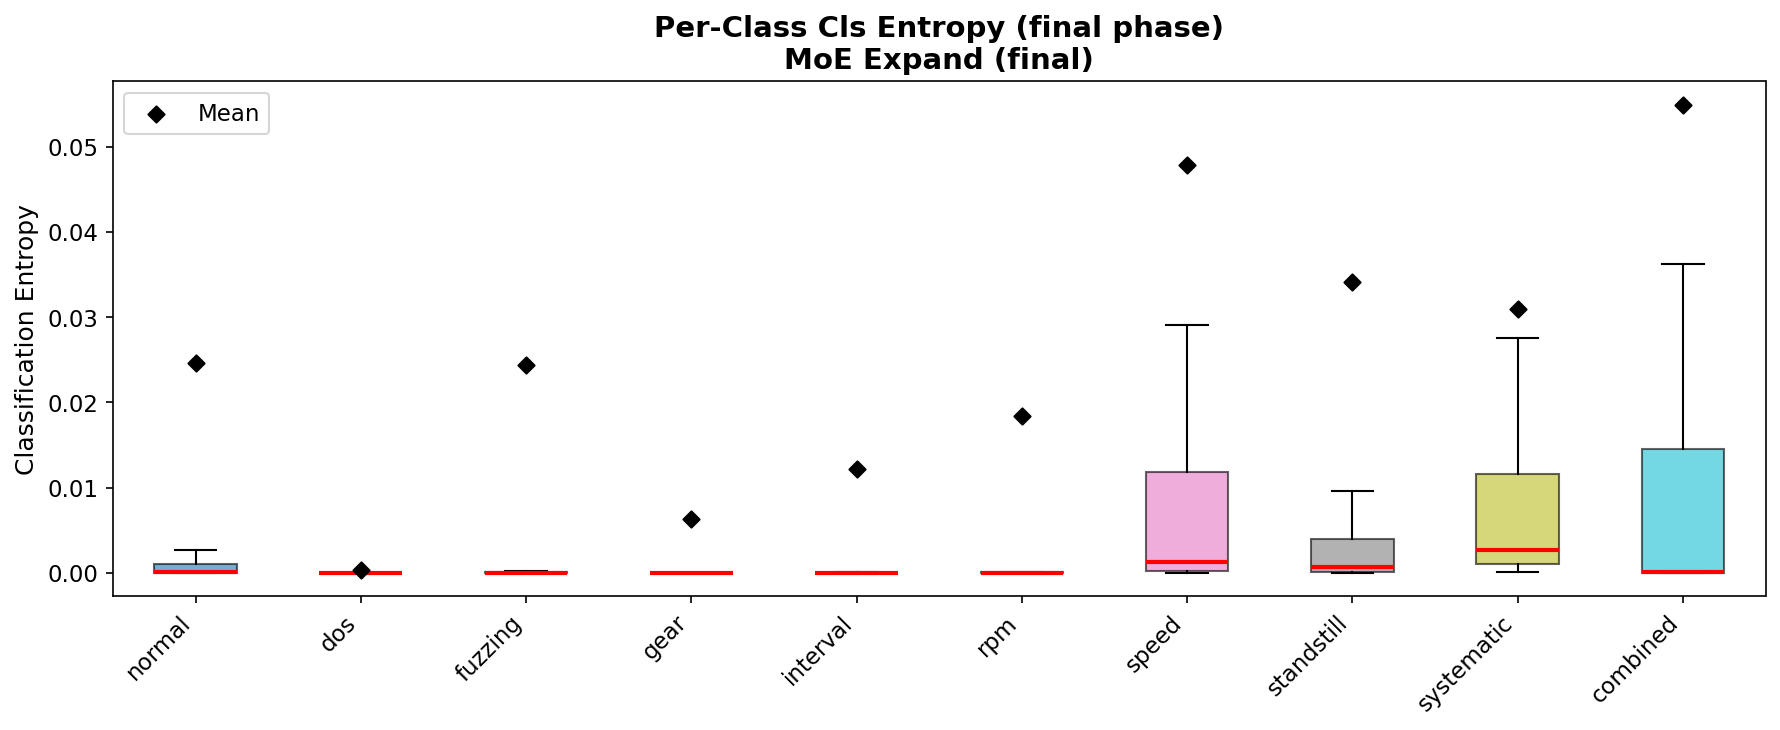

Class               Mean      Std   Median      Max
--------------------------------------------------
normal            0.0246   0.1025   0.0001   1.2717
dos               0.0004   0.0090   0.0000   0.2907
fuzzing           0.0244   0.1035   0.0000   0.8319
gear              0.0063   0.0534   0.0000   0.6942
interval          0.0121   0.0794   0.0000   1.2562
rpm               0.0183   0.0932   0.0000   0.8883
speed             0.0479   0.1368   0.0012   1.1314
standstill        0.0341   0.1284   0.0007   1.1445
systematic        0.0310   0.0993   0.0027   0.6929
combined          0.0549   0.1373   0.0001   0.8310


In [16]:
# 1. Per-class entropy distribution (final phase)
for config_name, res in all_results.items():
    decisions = res["decisions"]
    last_phase = decisions[-1]["phase"]
    last_n_exp = decisions[-1]["n_exp"]
    save_dir = CONFIGS[config_name]

    ckpt_path = os.path.join(save_dir, f"{last_phase}_best.pth")
    if not os.path.exists(ckpt_path):
        continue

    model, _ = load_phase_model(ckpt_path, last_n_exp)
    seen = set()
    for phase in PHASES:
        if "attacks" in phase:
            seen.update(phase["attacks"])
        else:
            seen.update(phase["new_attacks"])

    test_data = [w for w in all_test if w["label"] in seen]
    loader = DataLoader(WindowDataset(test_data), BATCH_SIZE,
                        shuffle=False, collate_fn=collate_fn,
                        num_workers=NUM_WORKERS, pin_memory=True)

    y_true, y_pred, cls_ent = evaluate_model(model, loader, device)

    # Per-class entropy boxplot
    class_order = sorted(set(y_true.tolist()))
    class_labels = [CLASS_NAMES[c] for c in class_order]
    class_entropies = [cls_ent[y_true == c] for c in class_order]

    fig, ax = plt.subplots(figsize=(12, 5))
    bp = ax.boxplot(class_entropies, labels=class_labels, patch_artist=True,
                    showfliers=False, medianprops=dict(color='red', linewidth=2))
    colors_box = plt.cm.tab10(np.linspace(0, 1, len(class_order)))
    for patch, c in zip(bp['boxes'], colors_box):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)

    # Add mean markers
    means = [np.mean(e) for e in class_entropies]
    ax.scatter(range(1, len(class_order)+1), means, marker='D', color='black',
               s=30, zorder=5, label='Mean')

    ax.set_ylabel('Classification Entropy')
    ax.set_title(f'Per-Class Cls Entropy (final phase)\n{config_name}', fontweight='bold')
    ax.legend()
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Print stats
    print(f"{'Class':<15} {'Mean':>8} {'Std':>8} {'Median':>8} {'Max':>8}")
    print("-" * 50)
    for c, lab, ents in zip(class_order, class_labels, class_entropies):
        print(f"{lab:<15} {np.mean(ents):>8.4f} {np.std(ents):>8.4f} "
              f"{np.median(ents):>8.4f} {np.max(ents):>8.4f}")
    del model


Evaluating:   0%|          | 0/93 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/17 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/99 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/14 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/99 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/6 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/101 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/33 [00:00<?, ?it/s]

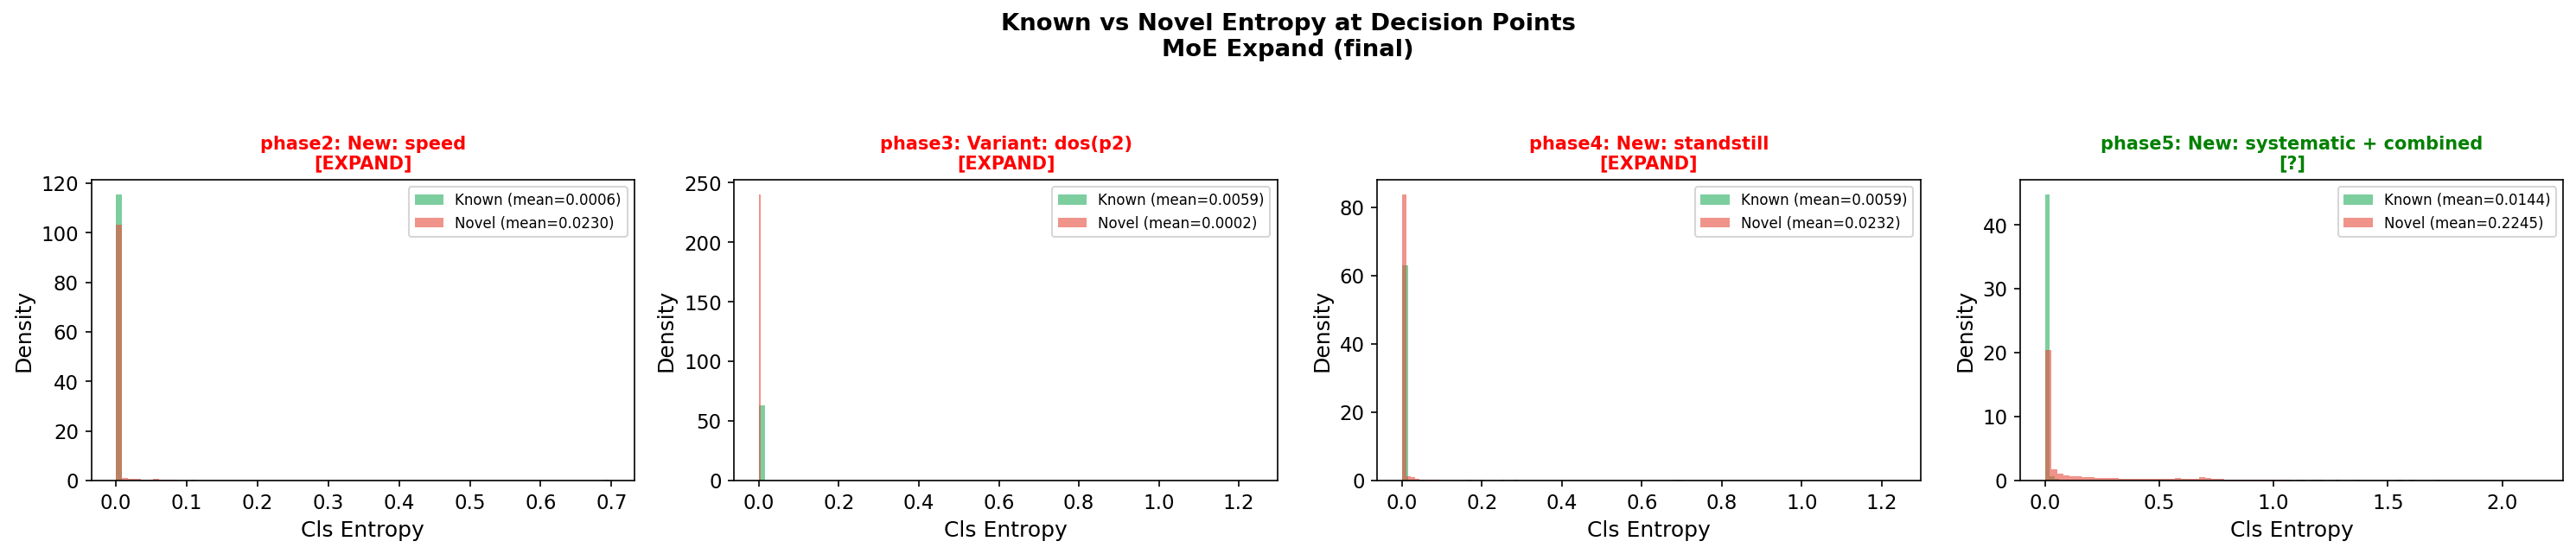

In [20]:
# Known vs Novel entropy at ALL decision points (phase 2-5)
for config_name, res in all_results.items():
    save_dir = CONFIGS[config_name]
    decision_phases = []

    seen = set()
    for pi, phase in enumerate(PHASES):
        if pi == 0:
            seen = set(phase["attacks"])
            continue
        new_attacks = set(phase["new_attacks"])
        seen_before = set(seen)
        seen.update(new_attacks)
        decision = res["decisions"][pi]["decision"] if pi < len(res["decisions"]) else "?"
        decision_phases.append((pi, phase, seen_before, new_attacks, decision))

    fig, axes = plt.subplots(1, len(decision_phases),
                              figsize=(len(decision_phases) * 5, 4))
    if len(decision_phases) == 1:
        axes = [axes]

    for ax, (pi, phase, seen_before, new_attacks, decision) in zip(axes, decision_phases):
        pname = phase["name"]

        # Find latest available checkpoint BEFORE this phase
        prev_ckpt = None
        for back in range(pi - 1, -1, -1):
            candidate = os.path.join(save_dir, f"{PHASES[back]['name']}_best.pth")
            if os.path.exists(candidate):
                prev_ckpt = candidate
                break

        if prev_ckpt is None:
            ax.set_title(f'{pname}: no checkpoint', fontsize=10)
            continue

        prev_ckpt_data = torch.load(prev_ckpt, map_location=device, weights_only=False)
        prev_n_exp = prev_ckpt_data.get("num_experts", NUM_EXPERTS_BASE)
        prev_model, _ = load_phase_model(prev_ckpt, prev_n_exp)

        # Known data entropy
        known_data = [w for w in all_val if w["label"] in seen_before]
        known_loader = DataLoader(WindowDataset(known_data), BATCH_SIZE,
                                   shuffle=False, collate_fn=collate_fn,
                                   num_workers=NUM_WORKERS)
        _, _, known_ent = evaluate_model(prev_model, known_loader, device)

        # Novel data entropy
        novel_data = [w for w in all_train if w["label"] in new_attacks]
        # For variant phase: filter only variant samples if they exist
        if phase.get("type") == "variant":
            variant_data = [w for w in novel_data if w.get("variant") == "dos_part2"]
            if len(variant_data) > 0:
                novel_data = variant_data

        if len(novel_data) == 0:
            ax.set_title(f'{pname}: no novel data found', fontsize=10)
            del prev_model
            continue

        novel_loader = DataLoader(WindowDataset(novel_data), BATCH_SIZE,
                                   shuffle=False, collate_fn=collate_fn,
                                   num_workers=NUM_WORKERS)
        _, _, novel_ent = evaluate_model(prev_model, novel_loader, device)

        # Plot
        ax.hist(known_ent, bins=80, alpha=0.6, color='#27AE60', density=True,
                label=f'Known (mean={np.mean(known_ent):.4f})')
        ax.hist(novel_ent, bins=80, alpha=0.6, color='#E74C3C', density=True,
                label=f'Novel (mean={np.mean(novel_ent):.4f})')
        ax.set_xlabel('Cls Entropy')
        ax.set_ylabel('Density')

        dec_color = 'red' if decision == 'expand' else 'green'
        ax.set_title(f'{pname}: {phase["desc"]}\n[{decision.upper()}]',
                     fontsize=10, fontweight='bold', color=dec_color)
        ax.legend(fontsize=8)
        del prev_model

    fig.suptitle(f'Known vs Novel Entropy at Decision Points\n{config_name}',
                 fontweight='bold', y=1.06)
    plt.tight_layout()
    plt.show()

## 7. Per-Class F1 Trajectory

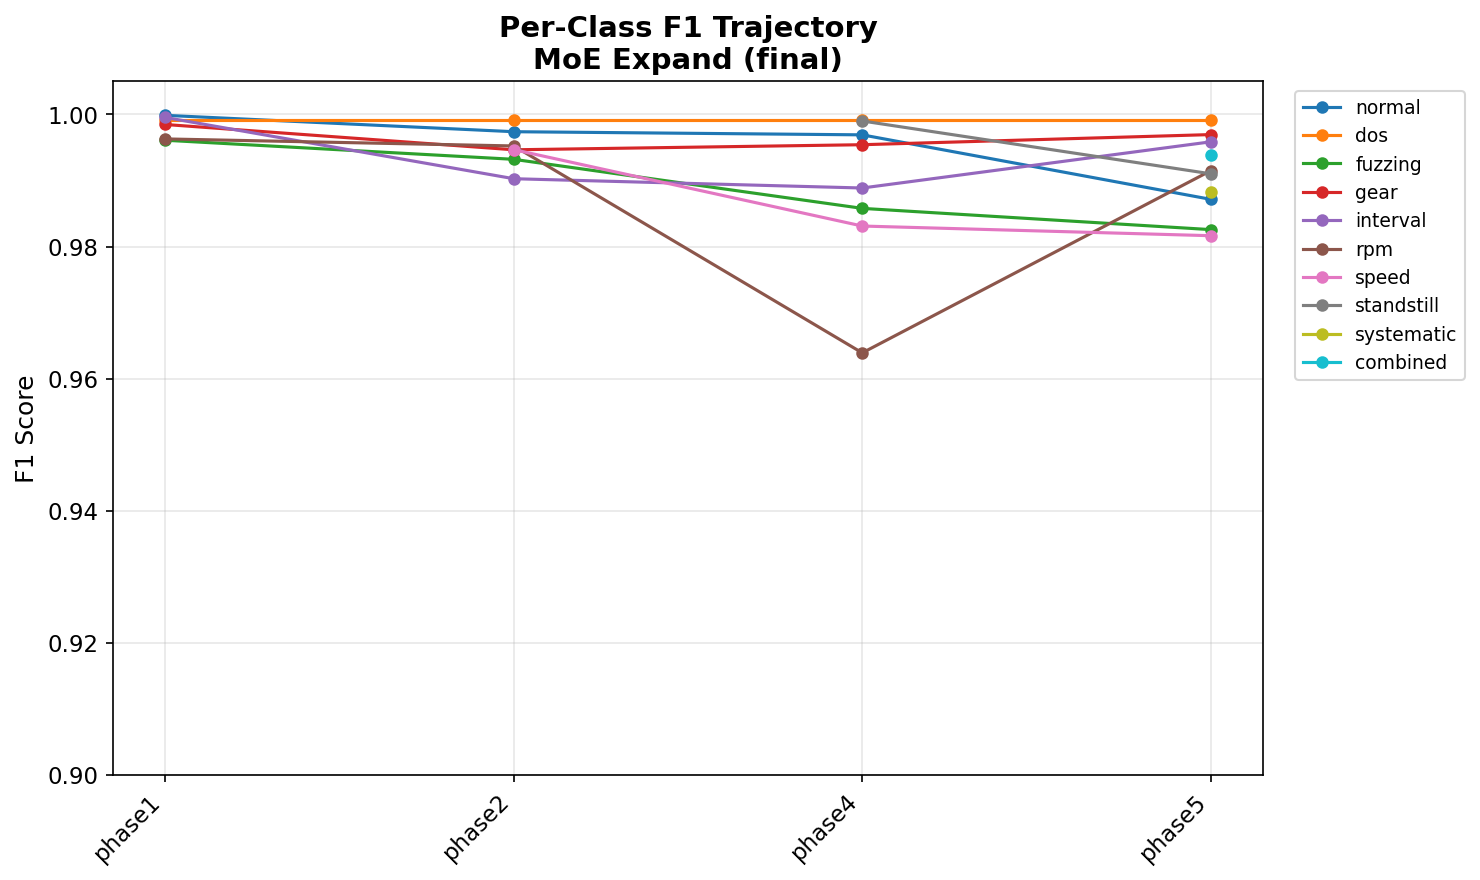

In [18]:
for config_name, res in all_results.items():
    phase_f1 = res["phase_f1"]
    phases = list(phase_f1.keys())

    all_classes = []
    for r in phase_f1.values():
        for c in r:
            if c not in all_classes:
                all_classes.append(c)

    fig, ax = plt.subplots(figsize=(10, 6))
    cmap = plt.cm.tab10
    for ci, cls in enumerate(all_classes):
        vals, xs = [], []
        for j, p in enumerate(phases):
            if cls in phase_f1[p]:
                vals.append(phase_f1[p][cls])
                xs.append(j)
        ax.plot(xs, vals, 'o-', color=cmap(ci / len(all_classes)),
                label=cls, linewidth=1.5, markersize=5)

    ax.set_xticks(range(len(phases)))
    ax.set_xticklabels(phases, rotation=45, ha='right')
    ax.set_ylabel('F1 Score')
    ax.set_ylim(0.9, 1.005)
    ax.set_title(f'Per-Class F1 Trajectory\n{config_name}', fontweight='bold')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 8. Summary Table

In [21]:
for config_name, res in all_results.items():
    phase_f1 = res["phase_f1"]
    macro_f1s = res["macro_f1s"]
    decisions = res["decisions"]

    print(f"\n{'='*80}")
    print(f"  {config_name}")
    print(f"{'='*80}")
    print(f"  {'Phase':<10} {'F1':>8} {'Experts':>8} {'Decision':>12} {'Description'}")
    print(f"  {'-'*75}")
    for d in decisions:
        f1 = macro_f1s.get(d['phase'], 0)
        print(f"  {d['phase']:<10} {f1:>8.4f} {d['n_exp']:>8} {d['decision']:>12} {d['desc']}")

    print(f"\n  Per-class F1 (final):")
    last = list(phase_f1.keys())[-1]
    for cls, f1 in sorted(phase_f1[last].items()):
        print(f"    {cls:<15} {f1:.4f}")

    # Forgetting
    all_classes = []
    first_f1, final_f1 = {}, {}
    for phase in phase_f1:
        for cls, f1 in phase_f1[phase].items():
            if cls not in all_classes:
                all_classes.append(cls)
                first_f1[cls] = f1
            final_f1[cls] = f1
    max_forget = max(first_f1[c] - final_f1[c] for c in all_classes)
    print(f"\n  Max forgetting: {max_forget:.4f}")
    print(f"  Final macro F1: {list(macro_f1s.values())[-1]:.4f}")



  MoE Expand (final)
  Phase            F1  Experts     Decision Description
  ---------------------------------------------------------------------------
  phase1       0.9977        6      initial Base: normal + dos(p1) + fuzzing + gear + interval + rpm
  phase2       0.9891        7       expand New: speed
  phase4       0.9751        8       expand New: standstill
  phase5       0.9754        9       expand New: systematic + combined

  Per-class F1 (final):
    combined        0.9938
    dos             0.9991
    fuzzing         0.9826
    gear            0.9969
    interval        0.9959
    normal          0.9871
    rpm             0.9915
    speed           0.9816
    standstill      0.9910
    systematic      0.9883

  Max forgetting: 0.0135
  Final macro F1: 0.9754


## 9. Save All Figures

In [ ]:
# Re-run any plot above with plt.savefig to save
# Or use: fig.savefig("./figures/plot_name.png", dpi=200, bbox_inches='tight')
print("Use plt.savefig() in any cell above to export figures for slides.")
